# Candidate follow-up: from "passes the pipeline" to "worth reporting"

The pipeline ends with a short list of signals that pass every automated test and match no
known object. The plan (§12) lists what comes next for a candidate that looks real:

1. **Is the signal real?** Look for it in *every* sector the star was observed in. A planet
   transits again, with the same depth, on the same clock. Noise and one-off systematics do not.
2. **Is it on the target?** Look at the pixels. During a transit the flux must disappear from
   the target's position, not from a neighbour's.
3. **Is it a planet?** Fit a physical transit model. The fitted shape implies a stellar density,
   which must match the star's. Combine everything into a false-positive probability.
4. **Then report it**: as a Community TOI (CTOI) on ExoFOP.

All checks are implemented in `src/followup.py`. This notebook explains the reasoning behind
each one and applies them to the candidates graded in `docs/REVIEW_sector104.md`:

| TIC | review grade | why it is here |
|---|---|---|
| 306101698 | A | the best-looking new signal; one concern (centroid shift) |
| 229804549 | B | plausible; broad wings, centroid shift |
| 304448456 | B | plausible; centroid shift |
| 161313862 | C | a 1.2 R⊕ signal with a 16σ centroid shift: decide on target or not |
| 394585043 | D | ranked #1 by the pipeline, but suspected not to repeat: a worked example of a failure |

`python -m src.followup --tics ...` runs all checks and stores the results in
`data/followup/{tic}/`. This notebook reads them where they exist, and calls the same functions
otherwise.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src import followup as fu

warnings.filterwarnings("ignore")
ROOT = Path("..")
dotenv.load_dotenv(ROOT / ".env")
SECTOR = int(os.environ["SECTOR"])
DATA_DIR = ROOT / "data"
FU = DATA_DIR / "followup"
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 220)

CANDS = {306101698: "A", 229804549: "B", 304448456: "B", 161313862: "C", 394585043: "D"}
CONTROL = 410153553  # LHS 3844 b, a confirmed planet: every check must come out "planet on target"
known = pd.read_parquet(DATA_DIR / "search" / f"sector_{SECTOR}_known.parquet").set_index("tic_id")
targets = pd.read_parquet(DATA_DIR / "targets" / f"sector_{SECTOR}.parquet").set_index("tic_id")
summ = {t: json.loads((FU / str(t) / "summary.json").read_text()) for t in CANDS if (FU / str(t) / "summary.json").exists()}
print("follow-up results on disk for:", list(summ))
known.loc[list(CANDS), ["period", "T0", "depth_ppm", "duration_h", "rp_earth", "snr", "SDE", "flags"]].assign(
    grade=pd.Series(CANDS)).round(4)

follow-up results on disk for: [306101698, 229804549, 304448456, 161313862, 394585043]


,period,T0,depth_ppm,duration_h,rp_earth,snr,SDE,flags,grade
tic_id,,,,,,,,,
306101698,2.8790,4180.7161,4882.4040,2.0101,3.0658,10.4593,17.0188,centroid,A
229804549,0.7321,4179.5834,2385.4468,1.5320,2.7551,17.2999,13.5300,centroid,B
304448456,0.5921,4179.2765,4356.8303,1.2341,1.9712,9.7105,15.1208,centroid,B
161313862,0.2929,4179.6908,2705.0932,0.5851,1.2302,7.9060,15.1711,centroid,C
394585043,4.4959,4179.8305,7335.4935,0.8149,2.4223,6.5562,10.1194,,D


## 1. Is the signal real? Every sector of the star

### 1.1 Why repetition is the strongest test

A transit search on one sector is a hypothesis test with thousands of trial periods. Even
after vetting, some surviving signals are lucky noise, and some are systematics that happen to
line up for 25 days. A real planet makes a sharp, falsifiable **prediction**: the same dip, of
the same depth and duration, every P days, in data taken years apart with different noise,
different detector pixels and different scattered light. Nothing else does that.

TESS observes most of the sky repeatedly, in sectors separated by one or two years. The five
stars above have between 3 and 11 sectors each. `fu.fetch_sectors` downloads one light curve
per sector (preferring SPOC, then TESS-SPOC, then QLP) and processes each with the
**pipeline's own** `load_raw` and `flatten_lc`, so every sector is treated exactly like the
discovery sector.

,sectors,points,baseline [yr]
TIC 306101698,8.0,55529.0,7.05
TIC 229804549,8.0,47177.0,7.88
TIC 304448456,3.0,24783.0,3.03
TIC 161313862,7.0,40473.0,7.88
TIC 394585043,10.0,59056.0,7.88


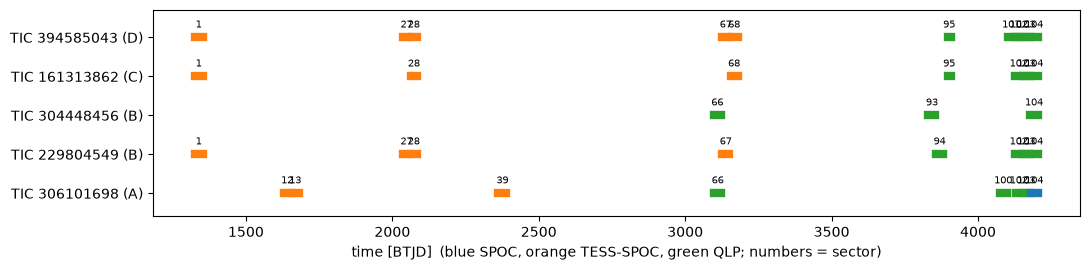

In [2]:
ms = {t: fu.fetch_sectors(t, FU / str(t)) for t in CANDS}
fig, ax = plt.subplots(figsize=(11, 2.8))
for i, (t, d) in enumerate(ms.items()):
    for (s, a), g in d.groupby(["sector", "author"]):
        ax.plot([g.time.min(), g.time.max()], [i, i], "-", lw=6, color={"SPOC": "C0", "TESS-SPOC": "C1", "QLP": "C2"}[a])
        ax.text(g.time.mean(), i + 0.25, str(s), ha="center", fontsize=7)
ax.set_yticks(range(len(ms)), [f"TIC {t} ({CANDS[t]})" for t in ms])
ax.set_xlabel("time [BTJD]  (blue SPOC, orange TESS-SPOC, green QLP; numbers = sector)")
ax.set_ylim(-0.6, len(ms) - 0.3)
plt.tight_layout()
pd.DataFrame({f"TIC {t}": {"sectors": len(d.sector.unique()), "points": len(d),
                           "baseline [yr]": (d.time.max() - d.time.min()) / 365.25} for t, d in ms.items()}).T.round(2)

### 1.2 A narrow-window search, sector by sector

We already know P. So instead of searching all periods again, TLS searches only a window of
±2 % around it, separately in every sector, then in all sectors except the discovery one, and
then in all sectors together.

**Why the window matters.** In the discovery search, TLS tried ~5,000 periods, and SDE ≥ 10 was
needed because the *largest* of 5,000 noise peaks is typically SDE 5–7 (the look-elsewhere
effect). In a ±2 % window there are only a few independent periods, so the look-elsewhere
penalty almost disappears. But the narrow window also means TLS *always* returns something
inside it.

**A trap in TLS itself.** TLS builds its period grid from the star and the baseline, then keeps
the periods inside [period_min, period_max]. If fewer than 100 remain, it silently **replaces
the grid by its default one, with no period limits at all**. One sector holds only ~25–50 grid
periods in ±2 % of a few-day period, so the first version of this notebook was in fact running
*full* searches in most single sectors (its tables showed periods far outside the window).
`fu._tls_window` now raises the grid's oversampling until the window holds ≥ 100 periods (the
`oversampling` column), which refines the grid without adding independent periods, and fails
loudly if TLS still leaves the window. The question is whether that something is the same signal: **the same period, the
same depth, transits at the predicted times.**

**Two traps, and the test that avoids them.** SDE measures how far the best peak stands above
the *rest of the periodogram*. In a ±2 % window, the "rest" is mostly the wings of the peak
itself, so SDE loses its meaning. LHS 3844 b, a confirmed planet, scores SDE ≈ 4.7 in each of
its sectors. TLS's `snr` is fine within one sector, but on multi-sector data it is unreliable:
it even comes out negative for some stars. So `fu.repetition` **counts independent sectors**.
A sector supports the signal if its *own* narrow search returns the same period, within the
precision one sector allows (0.5 %), with SNR ≥ 5.

**Not every sector can say no.** A sector with few points (the 30-minute cadence of 2018), a
short baseline or more noise may be unable to show the signal even if it is real. For every
sector we compute the SNR the discovery transit *would* reach there,
$\text{SNR}_{\rm exp} = (\delta/\sigma)\sqrt{N\,T_{14}/P}$ (column `snr_expected`). Only
**informative** sectors, with SNR_exp ≥ 7.5 (2.5σ above the detection cut), count against the
signal; a detection counts wherever it happens. The signal **repeats** if at least half of
the informative sectors (and at least 2) support it, with a median depth within a factor of 2
of the discovery depth. When no single sector is informative, the search on **all other
sectors combined** decides, if it is informative: it must return P at a depth within a factor
of 2. If nothing is informative, there is no verdict (`testable` is False).

**Eclipsing binaries at half their period.** A ±2 % window around P cannot return 2P, so each
sector is also searched around 2P (rows `sNNN@2P`, `fu.alias_search`). A planet has the same
depth at P and at 2P. A binary with two different eclipses, folded at P, averages them; at 2P
only the deeper one is in the box. A sector counts towards `repeats_at_alias` when the 2P depth
exceeds the P depth by ≥ 20 % and ≥ 2σ.

What to expect:

- **a real planet**: a detection in most sectors with enough transits, at the same period and
  depth, and a very high SDE when all sectors are combined (the transits add up coherently over
  years);
- **noise or a one-sector systematic**: random periods and depths in the other sectors, and a
  combined SDE no higher than the discovery sector alone.

The run takes minutes per star (TLS over a 7-year baseline), so the results stored by
`src/followup.py` are read here.

In [3]:
sec = {}
for t in CANDS:
    path = FU / str(t) / "sectors.csv"
    if path.exists():
        sec[t] = pd.read_csv(path)
    else:
        s, st = known.loc[t], targets.loc[t]
        sec[t] = fu.sector_search(ms[t], s.period, st.rad, st.mass, SECTOR, dur_h=s.duration_h, depth_ppm=s.depth_ppm)
        sec[t] = pd.concat([sec[t], fu.alias_search(ms[t], s.period, st.rad, st.mass)], ignore_index=True)
for t, d in sec.items():
    P = known.loc[t, "period"]
    d = d.assign(dP_rel=(d.period - P) / P)
    print(f"\nTIC {t} (grade {CANDS[t]}): discovery P = {P:.5f} d, depth {known.loc[t, 'depth_ppm']:.0f} ppm")
    print(d[["data", "author", "n_points", "oversampling", "period", "dP_rel", "depth_ppm", "snr", "snr_expected",
             "n_transits"]].round(4).to_string(index=False))


rep = pd.DataFrame({f"TIC {t} ({CANDS[t]})": fu.repetition(sec[t], known.loc[t, "period"], known.loc[t, "depth_ppm"], SECTOR)
                    for t in CANDS}).T
rep


TIC 306101698 (grade A): discovery P = 2.87897 d, depth 4882 ppm
             data             author  n_points  oversampling  period  dP_rel  depth_ppm     snr  snr_expected  n_transits
             s012          TESS-SPOC       932             8  2.8725 -0.0023  4251.7328  6.5569       10.0623           8
             s013          TESS-SPOC      1228             7  2.8722 -0.0024  2057.6954  4.9322       13.9533          10
             s039          TESS-SPOC      3722             7  2.8753 -0.0013  3283.7066  8.6164       13.6475          10
             s066                QLP     10239             8  2.8790 -0.0000  5475.5519  7.5919        8.6883           9
             s100                QLP      8037             8  2.8744 -0.0016  3205.1696  7.7126       14.5828           6
             s102                QLP      7910             9  2.8757 -0.0012  2693.6831  7.4155       13.9223           7
             s103                QLP      8140             8  2.8773 -0.0006  44

,n_other_sectors,n_informative,n_same_period,n_same_informative,n_alias_period,depth_ratio,combined_informative,combined_repeats,combined_depth_ratio,basis,testable,repeats,repeats_at_alias
TIC 306101698 (A),7,7,6,6,1,0.771694,True,True,0.799936,sectors,True,True,False
TIC 229804549 (B),7,7,2,2,0,0.451279,True,False,0.136281,sectors,True,False,False
TIC 304448456 (B),2,0,2,0,1,2.132518,True,False,2.016541,sectors,True,False,True
TIC 161313862 (C),6,4,0,0,0,NaN,True,False,0.486785,sectors,True,False,False
TIC 394585043 (D),9,0,0,0,0,NaN,True,False,0.304792,combined,True,False,False


The table above applies the counting rule to the individual-sector rows. What the sectors say:

- **TIC 306101698 repeats.** Six of the seven other sectors (TESS-SPOC 2019–2021, QLP
  2025–2026), all informative, independently return 2.872–2.879 d, at ~75 % of the discovery
  depth. The signal is real and periodic. Whether it is a *planet on this star* is a separate
  question (§2).
- **TIC 304448456 is an eclipsing binary found at half its period.** Both other sectors return
  0.5923 d at SNR 12–17, but twice as deep as in sector 104 (7,200–11,400 ppm vs 4,300 ppm), and
  in sector 66 the search at 2P finds a significantly deeper dip than at P: two different
  eclipses averaged at P. (Vetting v3 now rejects this signal anyway: its duration is 1.6× what
  a planet around this star can have.)
- **TIC 229804549** comes back at the same period in only 2 of 7 informative sectors, at less
  than half the depth. That is not convincing.
- **TIC 161313862 and TIC 394585043 never come back.** For TIC 161313862, 4 of the 6 other
  sectors were sensitive enough to show it, and none does. TIC 394585043 was ranked #1 by the
  pipeline. No single other sector could have shown it (expected SNR 4–7, look at
  `snr_expected`), but the nine together could (expected SNR 16). Searched together, 51,000
  points over 8 years return a different period at a third of the depth. It was noise, or a
  systematic, in one sector.

A visual check: fold every sector on the combined ephemeris. A real transit appears as the same
dip in each panel.

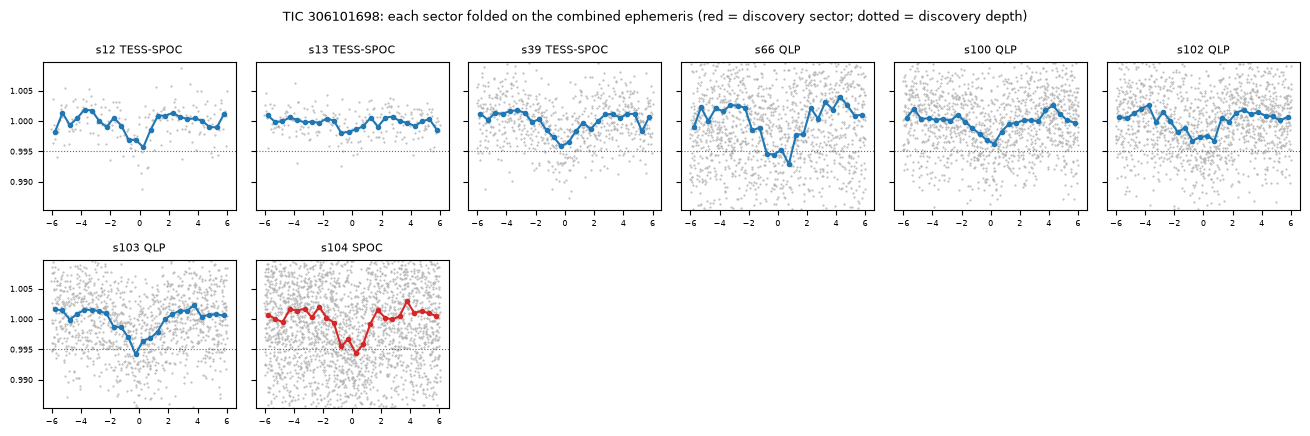

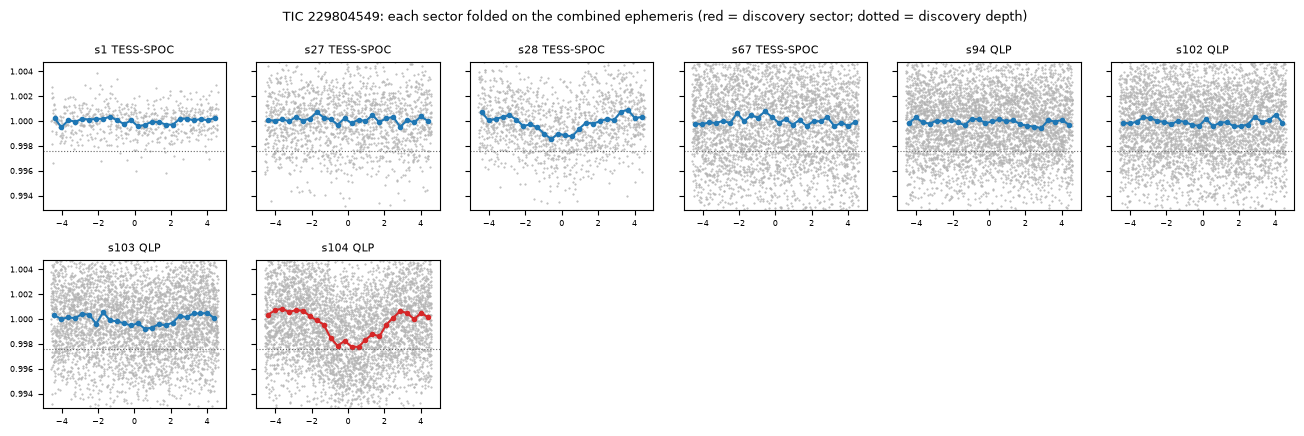

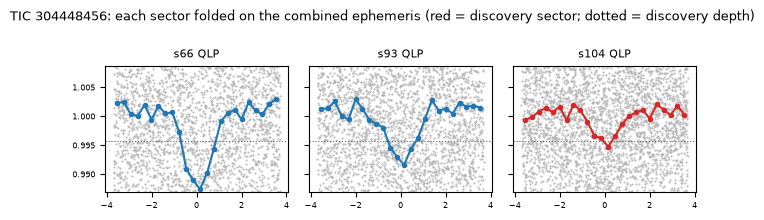

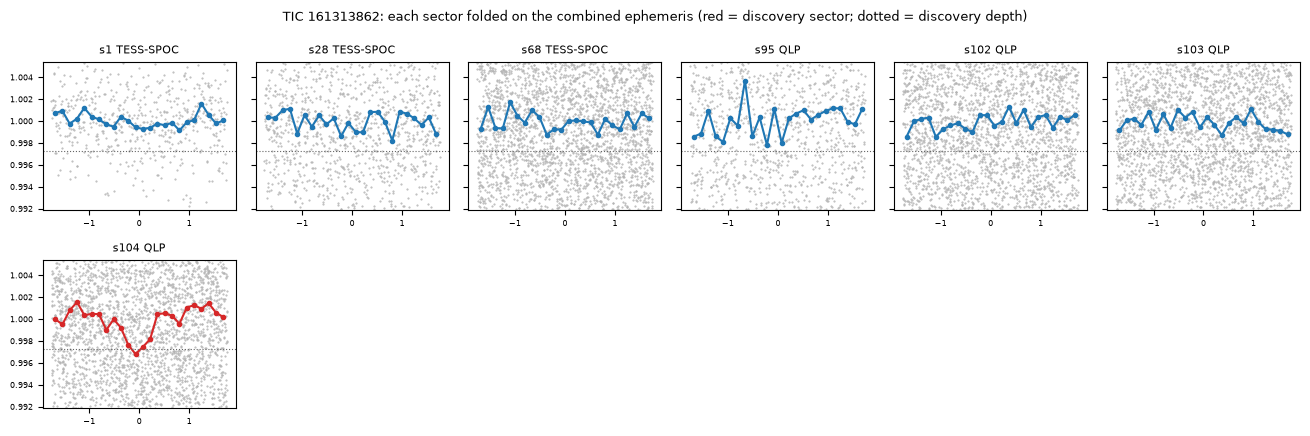

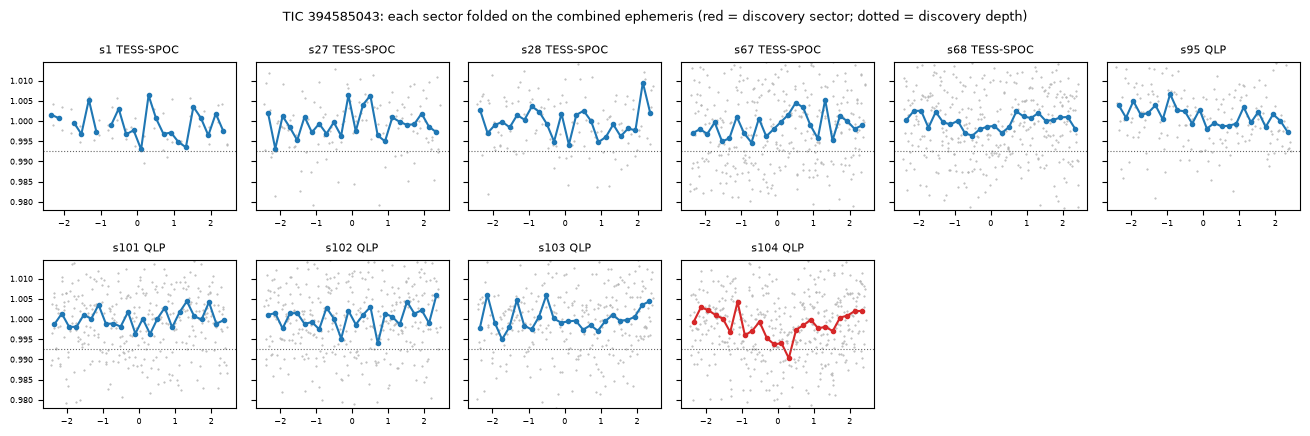

In [4]:
def fold_by_sector(t, P=None, T0=None, max_cols=6):
    d = ms[t]
    row = sec[t][sec[t]["data"] == "all sectors"].iloc[0]
    P = P or row.period
    T0 = T0 or row.T0
    dur = known.loc[t, "duration_h"]
    depth = known.loc[t, "depth_ppm"] / 1e6
    sectors = sorted(d.sector.unique())
    ncol = min(len(sectors), max_cols); nrow = int(np.ceil(len(sectors) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.2 * ncol, 2.2 * nrow), sharey=True, squeeze=False)
    w = 3 * dur
    for ax, s in zip(axes.flat, sectors):
        g = d[d.sector == s]
        x = ((g.time - T0 + P / 2) % P - P / 2) * 24
        m = np.abs(x) < w
        ax.plot(x[m], g.flux[m], ".", ms=1, color="0.7")
        e = np.linspace(-w, w, 25); i = np.digitize(x[m], e)
        b = [g.flux[m][i == j].mean() if (i == j).any() else np.nan for j in range(1, 25)]
        ax.plot(0.5 * (e[1:] + e[:-1]), b, "o-", ms=3, color="C3" if s == SECTOR else "C0")
        ax.axhline(1 - depth, color="0.4", ls=":", lw=0.8)
        ax.set_title(f"s{s} {g.author.iloc[0]}", fontsize=8); ax.tick_params(labelsize=6)
    for ax in list(axes.flat)[len(sectors):]:
        ax.axis("off")
    axes[0, 0].set_ylim(1 - 3 * depth, 1 + 2 * depth)
    fig.suptitle(f"TIC {t}: each sector folded on the combined ephemeris (red = discovery sector; dotted = discovery depth)",
                 fontsize=9)
    plt.tight_layout()


for t in CANDS:
    fold_by_sector(t)

### 1.3 The payoff of a long baseline: the ephemeris

With one sector, the period is known to ~10⁻³ d. Projected a year ahead, the predicted transit
time is then uncertain by hours, too vague to schedule a telescope. With sectors spread over
years, the transits pin down the period to ~10⁻⁵ d. The uncertainty of a predicted transit at
epoch n is $\sigma_t = \sqrt{\sigma_{T_0}^2 + (n\,\sigma_P)^2}$ (notebook 6, §5).

In [5]:
rows = {}
for t, d in sec.items():
    one = d[d["data"] == f"s{SECTOR:03d}"].iloc[0]
    allr = d[d["data"] == "all sectors"].iloc[0]
    n_year = 365.25 / allr.period
    rows[f"TIC {t}"] = {"sigma_P one sector [d]": one.period_unc, "sigma_P all sectors [d]": allr.period_unc,
                        "transit time 1 yr ahead, one sector [h]": n_year * one.period_unc * 24,
                        "... all sectors [h]": n_year * allr.period_unc * 24}
pd.DataFrame(rows).T

,sigma_P one sector [d],sigma_P all sectors [d],"transit time 1 yr ahead, one sector [h]",... all sectors [h]
TIC 306101698,0.010530,0.000094,32.087310,0.286179
TIC 229804549,0.003052,0.000018,36.531847,0.216284
TIC 304448456,0.001400,0.000029,20.723183,0.428523
TIC 161313862,0.000486,0.000003,14.557505,0.082515
TIC 394585043,0.013395,0.000190,26.123674,0.370403


(TLS's `period_uncertainty` is the half-width of the periodogram peak, a conservative
estimate. The MCMC fit of §3 gives the statistically proper uncertainty.)

## 2. Is it on the target? Pixels and neighbours

### 2.1 Difference imaging

A TESS pixel is 21″ wide, so several stars share every aperture (notebook 6, §6). The
light-curve centroid (vetting's soft flag) says the light *distribution* changes during
transit, not where the change happens. The direct test uses the pixels themselves:

1. download a 15 × 15-pixel cutout of the full-frame images around the star (TESScut);
2. for every transit, average the images **in transit** and **just before and after**;
3. subtract: out-of-transit − in-transit. The **difference image** is a map of where flux
   disappeared;
4. compare its centroid with the centroid of the out-of-transit image near the target (the
   target's own light). Measuring the offset relative to the star's *own* image, rather than to
   its catalog position, cancels errors in the PSF and the coordinate system. This is what
   Kepler's and TESS's Data Validation report;
5. also find the **strongest flux loss anywhere in the cutout**, in units of its scatter from
   transit to transit. A source a few pixels away would sit outside the centroid window.

For a transit on the target, the difference image looks like the star's own image (its point
spread function, PSF) centred on the target. For a blend, it is centred on the neighbour.
Taking the difference transit by transit, with the out-of-transit images taken close in time,
cancels slow changes in the background. Bootstrapping over transits (resampling them with
replacement and recomputing the centroid) gives the centroid's uncertainty.

**Decision rule** (`off_target` in `src/followup.py`): the source is off target if the
difference centroid is > 0.5 px from the target's light at > 3σ, **or** if the strongest flux
loss lies > 1.5 px from the target with S/N > 5 and is more than twice as strong as the loss at
the target. LHS 3844 b, a confirmed planet, is included as a control: it must come out on
target.

**Limits.** With faint stars, shallow transits and 21″ pixels, the difference image is noisy.
An offset below ~0.3 px (≈ 6″) is unresolvable, and a neighbour closer than that cannot be
excluded this way.

,n_transits,offset_px,offset_err_px,offset_sigma,strongest_loss_dist_px,strongest_loss_snr,loss_snr_at_target,off_target
410153553,54,0.042985,0.075298,0.570864,0.814836,13.692374,11.150037,False
306101698,8,1.240307,0.278985,4.445782,2.007769,6.814083,2.343101,True
229804549,32,2.521015,0.720225,3.500313,5.845918,27.323764,-0.501947,True
304448456,41,0.93021,0.034745,26.772674,2.032305,28.749572,0.820039,True
161313862,84,2.516266,1.448995,1.736559,2.632417,2.404197,0.098779,False
394585043,6,0.81627,1.203884,0.678031,1.228294,4.337583,1.274567,False


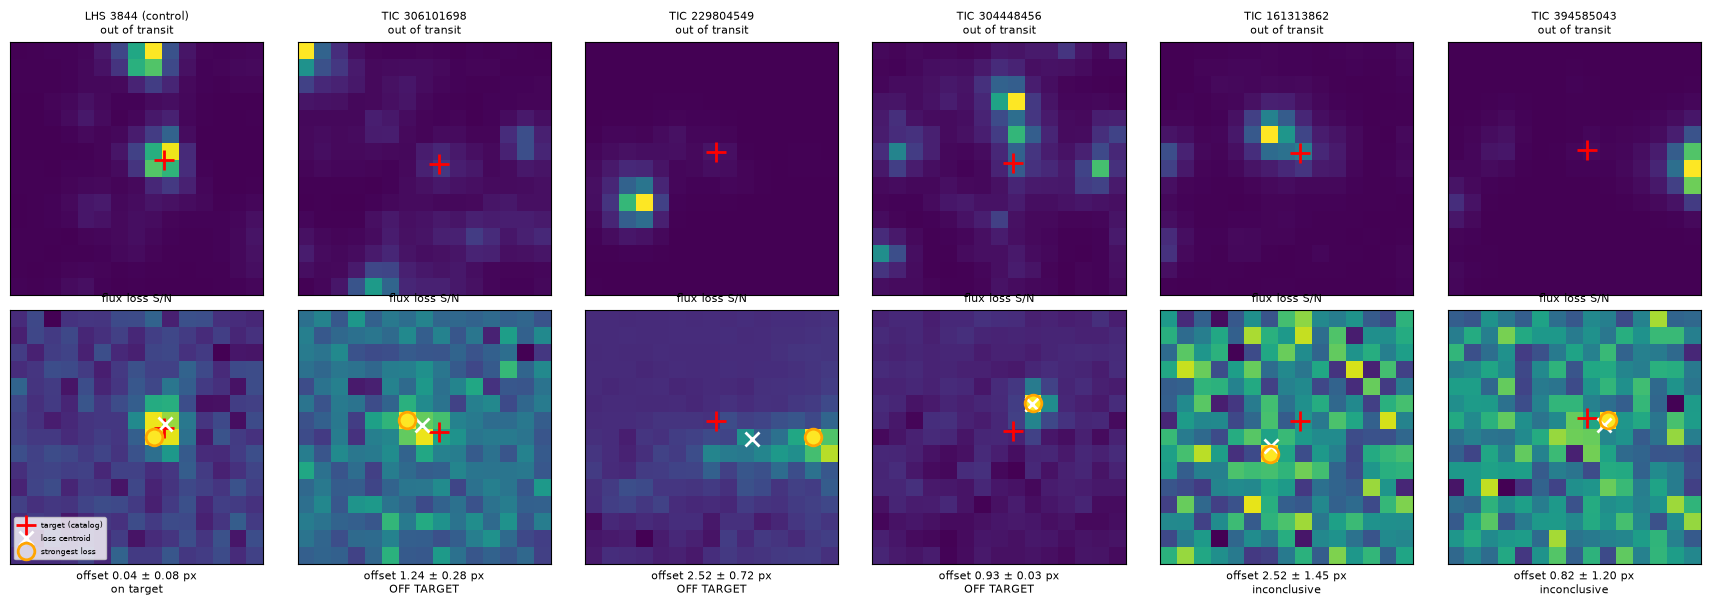

In [6]:
from astropy.coordinates import SkyCoord

stars = [CONTROL] + list(CANDS)
di = {}
for t in stars:
    s = known.loc[t]
    (FU / str(t)).mkdir(parents=True, exist_ok=True)
    di[t] = fu.difference_image(t, targets.loc[t], s.period, s.T0, s.duration_h, SECTOR, FU / str(t))

fig, axes = plt.subplots(2, len(stars), figsize=(2.9 * len(stars), 6.0))
for j, t in enumerate(stars):
    z = np.load(FU / str(t) / f"diffimage_s{SECTOR}.npz")
    for i, (img, title) in enumerate([(z["oot"], "out of transit"), (z["snr_img"], "flux loss S/N")]):
        ax = axes[i, j]
        ax.imshow(img, origin="lower", cmap="viridis")
        ax.plot(*z["target"], "r+", ms=14, mew=2, label="target (catalog)")
        if i == 1:
            ax.plot(*z["centroid"], "wx", ms=10, mew=2, label="loss centroid")
            ax.plot(*z["strongest"], "o", ms=12, mfc="none", mec="orange", mew=2, label="strongest loss")
        name = "LHS 3844 (control)" if t == CONTROL else f"TIC {t}"
        ax.set_title(f"{name}\n{title}" if i == 0 else title, fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
    r = di[t]
    state = ("OFF TARGET" if r["off_target"] else
             "inconclusive" if (r["strongest_loss_snr"] < 5 and r["loss_snr_at_target"] < 3) else "on target")
    axes[1, j].set_xlabel(f"offset {r['offset_px']:.2f} ± {r['offset_err_px']:.2f} px\n{state}", fontsize=8)
axes[1, 0].legend(fontsize=6, loc="lower left")
plt.tight_layout()
cols = ["n_transits", "offset_px", "offset_err_px", "offset_sigma", "strongest_loss_dist_px", "strongest_loss_snr",
        "loss_snr_at_target", "off_target"]
pd.DataFrame({t: {k: di[t][k] for k in cols} for t in stars}).T.round(2)

The control behaves as a planet must: the flux loss is centred on LHS 3844 (S/N 11 at the target,
offset 0.04 ± 0.08 px). Three candidates do the opposite. The strongest loss lies 2–6 px away,
at S/N 7–29, while the target pixel shows little or nothing:

- **TIC 306101698**: loss 2 px (~42″) away; centroid offset 4.4σ. The repeating signal of §1 is
  an eclipse on a neighbour;
- **TIC 304448456**: S/N 29 at 2 px vs 0.8 at the target: the 2P eclipsing binary of §1 is a
  neighbour;
- **TIC 229804549**: S/N 27 at 6 px.

**Crowded fields.** The offset is measured from the target's own out-of-transit light centroid,
and from its catalog position. A signal is called off target only if the flux loss is away from
both: with many neighbours in the aperture the light centroid itself is pulled towards them
(§7 has a case, TIC 214311908, whose loss sits 0.3 px from the catalog position but 0.76 px from
the light centroid).

For TIC 161313862 and 394585043 no significant loss appears anywhere (S/N ≤ 4). With signals
that do not repeat, that is expected: the pixels have nothing to locate. The verdict table
reports these as *inconclusive*, not "on target".

### 2.2 Which neighbours could cause the dip at all?

A neighbour can only produce our dip if it is bright enough. If a star fainter than the target
by Δm eclipsed *completely*, the total light would drop by at most $10^{-0.4\,\Delta m}$ of the
target's flux. A dip of depth δ therefore needs a neighbour with

$$\Delta m < -2.5\log_{10}\delta .$$

For δ = 5,000 ppm that is Δm < 5.75 mag. Every fainter neighbour is excluded *whatever* it
does. This is the "nearby eclipsing binary" (NEB) check TFOP runs with ground-based photometry,
which resolves stars a few arcseconds apart and can check each bright-enough neighbour
directly. We list the Gaia DR3 stars within 3 pixels and mark those that pass the
criterion. (Gaia G is used for both stars. For similar red stars the G and TESS magnitude
differences agree to a few tenths.)

In [7]:
for t in CANDS:
    s, st = known.loc[t], targets.loc[t]
    g = fu.gaia_neighbours(fu.target_coord(st, s.T0), s.depth_ppm)
    dm = -2.5 * np.log10(s.depth_ppm / 1e6)
    n_ok = int(g.could_cause_dip.iloc[1:].sum()) if len(g) else 0
    print(f"TIC {t}: depth {s.depth_ppm:.0f} ppm -> neighbours need dG < {dm:.2f}; "
          f"{len(g) - 1} Gaia stars within 63\", {n_ok} bright enough")
    if n_ok:
        print(g[g.could_cause_dip].iloc[1:][["Source", "sep_arcsec", "Gmag", "dG", "BP-RP"]].round(2).to_string(index=False))

TIC 306101698: depth 4882 ppm -> neighbours need dG < 5.78; 78 Gaia stars within 63", 48 bright enough
             Source  sep_arcsec  Gmag   dG  BP-RP
5912322516480139136        6.01 19.30 5.08   1.17
5912322512188007040       12.56 19.38 5.16   2.30
5912322546544025600       13.91 19.17 4.94   1.89
5912275581083263872       14.85 17.74 3.52   0.90
5912322512184256768       16.03 18.73 4.51   0.85
5912275615446491136       22.16 18.80 4.57   1.46
5912322516480140288       22.90 19.86 5.64   0.87
5912322550839881216       23.81 18.36 4.14   1.01
5912322516488985856       24.47 17.68 3.45   0.87
5912322512184239872       25.10 18.88 4.66   2.69
5912322550846844288       27.88 19.66 5.44   0.80
5912322550846844544       28.14 17.03 2.80   1.24
5912322550839879296       28.45 19.37 5.15   0.85
5912275611141412480       28.81 17.73 3.51   1.00
5912275615443003776       29.08 15.85 1.62   0.87
5912275581083263104       31.06 18.90 4.67   1.79
5912275581083263232       32.21 17.73 3.51   1.

## 3. Is it a planet? Fitting a physical transit model

### 3.1 The model and its parameters

TLS fits a template. A physical fit asks which planet, on which orbit, around this star,
reproduces the light curve. On a circular orbit the transit shape depends on:

| parameter | meaning | what in the light curve constrains it |
|---|---|---|
| $T_0$, P | ephemeris | the transit times |
| k = Rp/R★ | size ratio | the depth (δ ≈ k² × a limb-darkening factor) |
| b | impact parameter: how far from the disk centre the planet crosses, in R★ | ingress/egress length relative to the total duration |
| a/R★ | orbit size in stellar radii | the total duration, given P and b |
| q₁, q₂ | limb darkening (Kipping 2013 parametrisation of the quadratic law) | the curvature of the transit bottom |

**Stellar density from the light curve.** Kepler's law links a/R★ and P to the density of the
star being transited, with no other input (Seager & Mallén-Ornelas 2003):

$$\rho_\star = \frac{3\pi}{G P^2}\left(\frac{a}{R_\star}\right)^3 .$$

That is a strong consistency check. If the dip comes from our M dwarf (ρ ≈ 5–20 g/cm³), the
fitted density must agree with the TIC's. A blend on a larger background star implies a much
lower density, and an eccentric orbit can bias it by a factor of a few.

### 3.2 Bayesian fitting with MCMC

We want the **posterior** probability of the parameters given the data,
p(θ | data) ∝ p(data | θ) p(θ): likelihood times prior. The likelihood is Gaussian,
$\ln p(\text{data} | \theta) = -\tfrac12 \sum_i (f_i - m_i(\theta))^2/\sigma_i^2$. The priors are
uniform within physical bounds (k < 0.5, 0 ≤ b < 1 + k, 1.5 < a/R★ < 200, q₁, q₂ ∈ [0, 1]).

**MCMC** (Markov-chain Monte Carlo) draws samples from the posterior without computing it on a
grid, which would be hopeless in 7 dimensions. We use `emcee` (Foreman-Mackey et al. 2013), an
*affine-invariant ensemble sampler*: 32 "walkers" move through parameter space, each proposing
a step along the line to another walker (a "stretch move"). Proposals are accepted with
probability min(1, posterior ratio). After a **burn-in** (here the first third of the chain,
discarded), the walkers' positions are samples from the posterior. Medians and 16th/84th
percentiles give the values and 1σ uncertainties.

Details that matter:

- **Masked detrending.** The fit uses light curves re-flattened with the transits *masked*
  (`fu.masked_flatten`). The 0.5-day biweight otherwise removes up to ~25 % of a long transit's
  depth (`docs/NOTES_decisions.md`).
- **Exposure smearing.** Each sector's cadence (120 s, 200 s, 600 s) is integrated over
  (`batman` supersampling). A 10-minute exposure turns a sharp ingress into a ramp.
- **Reference epoch.** $T_0$ is placed near the middle of the data, which decorrelates it from
  P.

A fit takes a few minutes per star. Stored chains are reused.

In [8]:
fits = {}
for t in CANDS:
    path = FU / str(t) / "fit.json"
    if path.exists():
        fits[t] = json.loads(path.read_text())
rows = {}
for t, f in fits.items():
    g = lambda k: f"{f[k]['median']:.3f} +{f[k]['plus']:.3f} -{f[k]['minus']:.3f}"
    rows[f"TIC {t}"] = {"P [d]": f"{f['P']['median']:.6f} ± {0.5 * (f['P']['plus'] + f['P']['minus']):.6f}",
                        "Rp/R*": g("k"), "b": g("b"), "a/R*": g("a_rs"), "Rp [R⊕]": g("rp_earth"),
                        "rho* transit [g/cm3]": g("rho_star_transit"), "rho* TIC [g/cm3]": f"{f['rho_star_tic']:.2f}",
                        "rho ratio": f"{f['rho_ratio_median']:.2f}", "sectors": len(f["sectors"]),
                        "acceptance": f"{f['acceptance']:.2f}"}
pd.DataFrame(rows).T

,P [d],Rp/R*,b,a/R*,Rp [R⊕],rho* transit [g/cm3],rho* TIC [g/cm3],rho ratio,sectors,acceptance
TIC 306101698,2.876822 ± 0.000007,0.052 +0.010 -0.004,0.404 +0.279 -0.285,6.042 +0.744 -0.935,2.569 +0.502 -0.287,0.504 +0.210 -0.200,6.99,0.07,8,0.31
TIC 229804549,0.732161 ± 0.000071,0.025 +0.002 -0.002,0.305 +0.220 -0.210,1.661 +0.152 -0.102,1.593 +0.174 -0.154,0.162 +0.049 -0.028,4.21,0.04,8,0.19
TIC 304448456,0.592389 ± 0.000001,0.082 +0.027 -0.010,0.593 +0.313 -0.399,2.157 +0.383 -0.578,2.753 +0.860 -0.405,0.541 +0.342 -0.329,14.08,0.04,3,0.25
TIC 161313862,0.292609 ± 0.000031,0.025 +0.007 -0.005,0.458 +0.338 -0.321,2.671 +1.680 -0.740,0.662 +0.187 -0.134,4.210 +14.003 -2.619,21.26,0.20,7,0.17
TIC 394585043,4.494149 ± 0.001033,0.043 +0.024 -0.007,0.629 +0.343 -0.420,10.069 +7.627 -5.162,1.347 +0.708 -0.232,0.957 +4.232 -0.846,15.50,0.06,10,0.22


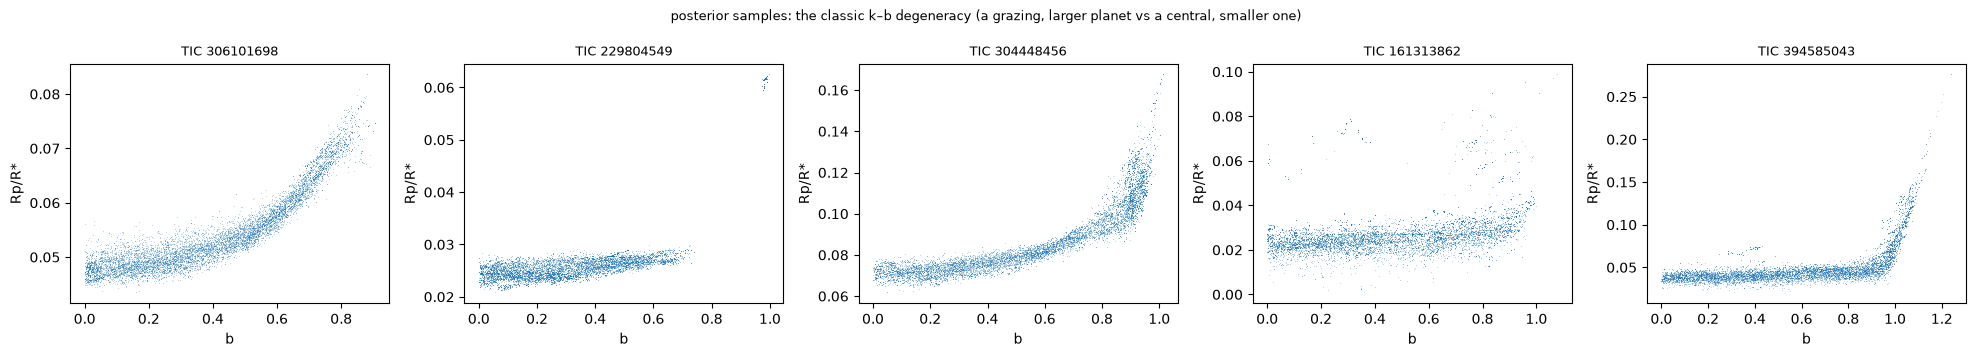

In [9]:
names = ["k", "b", "log10_a_rs"]
labels = ["Rp/R*", "b", "log10 a/R*"]
fig, axes = plt.subplots(1, len(fits), figsize=(4 * len(fits), 3.6), squeeze=False)
for ax, t in zip(axes.flat, fits):
    ch = np.load(FU / str(t) / "fit_samples.npz")["chain"]
    ax.plot(ch[:, 3], ch[:, 2], ",", alpha=0.3)
    ax.set_xlabel("b"); ax.set_ylabel("Rp/R*"); ax.set_title(f"TIC {t}", fontsize=9)
plt.suptitle("posterior samples: the classic k–b degeneracy (a grazing, larger planet vs a central, smaller one)",
             fontsize=9)
plt.tight_layout()

The k–b plane shows the most common degeneracy of transit fits. A shallow, short-ingress
transit is fit equally well by a smaller planet crossing the centre (low b) or a larger one
grazing the limb (high b). Only a well-resolved ingress and egress breaks it, which needs short
cadence and high SNR. The density check is less affected, because a/R★ and b are constrained
together by the total duration.

**The density check.** The control, LHS 3844 b, comes out at Rp = 1.32 ± 0.10 R⊕ (published
1.30) with a fitted stellar density 0.8× the TIC value, consistent with 1 within its error. The
fit works. Every candidate gives **0.04–0.2×**: its dips last 2–3× longer than a transit
across *this* M dwarf can. That is what a dip produced on a larger, less dense star looks
like, i.e. a blend, which agrees with the pixels. (For TIC 161313862 and 394585043, whose
signals do not repeat, the multi-sector fit has no real transit to fit, and its parameters mean
nothing.)

### 3.3 False-positive probability (TRICERATOPS)

TRICERATOPS (Giacalone et al. 2021) turns all of this into one number. It considers every
scenario that could produce the dip, each with its own transit/eclipse light-curve model:

| scenario | meaning |
|---|---|
| TP | transiting planet on the target |
| EB, EBx2P | eclipsing binary on the target (at P, or at 2P) |
| PTP, PEB, STP, SEB | planet or EB around an unresolved bound companion of the target |
| DTP, DEB | planet or EB on an unresolved chance-aligned background star |
| NTP, NEB | planet or EB on a known nearby star (from Gaia/TIC) |

For each, it computes the **marginal likelihood** of the folded light curve (the fit
probability averaged over that scenario's parameter priors, by Monte-Carlo integration with N
draws) times the scenario's **prior** (how common EBs, companions and background stars are).
Normalised over all scenarios this gives a probability for each. **FPP** = 1 − P(TP), and
**NFPP** = the total probability of the nearby-star scenarios.

The published rule for *statistical validation* is FPP < 0.015 and NFPP < 0.001. With TESS
photometry alone, and without high-resolution imaging, most small-planet candidates reach
"likely planet" (FPP < 0.5) but not validation. Validation needs the ground-based follow-up
TRICERATOPS was designed to combine with.

In [10]:
fpps = {t: summ[t].get("fpp", {}) for t in summ}
pd.DataFrame({f"TIC {t}": {"FPP": f.get("FPP"), "NFPP": f.get("NFPP"), "draws": f.get("n_draws"),
                           "top scenario": (f.get("scenarios") or [{}])[0].get("scenario"),
                           "error": f.get("error", "")} for t, f in fpps.items()}).T

,FPP,NFPP,draws,top scenario,error
TIC 306101698,0.900149,0.900141,20000,NEB,
TIC 229804549,1.0,1.0,20000,NEBx2P,
TIC 304448456,0.985415,0.985301,20000,NTP,
TIC 161313862,0.27138,0.243563,20000,TP,
TIC 394585043,0.059061,0.000078,20000,TP,


For the control, TRICERATOPS gives FPP = 0.015 and NFPP = 0, at the validation threshold,
for a planet that was indeed statistically validated. For the three blends found in §2, the
nearby-star scenarios (NEB, NTP, NEBx2P) dominate with FPP ≥ 0.90, independently of the pixel
analysis.

**The lesson of the last two rows.** TIC 161313862 (FPP 0.27) and TIC 394585043 (FPP 0.06)
look *good* by FPP, yet their signals do not exist in the other sectors. TRICERATOPS answers
"*given* that this dip is astrophysical, what produced it?". It has no scenario for noise or
instrumental systematics. That is why the follow-up order is: **first establish that the signal
is real (repetition), then where it is (pixels), and only then what it is (fit, FPP).**

## 4. Verdicts

The verdict combines the checks in order of decisiveness. A failure of an earlier check
overrides later successes:

1. **repeats**: at least half of the other sectors independently return the same period, with
   a consistent depth (`fu.repetition`, §1.2). Returning only at 2P or P/2 points to an eclipsing
   binary;
2. **on target**: the difference image does not place the flux loss on a neighbour (§2.1);
3. **density**: fitted stellar density within a factor 3 of the TIC value;
4. **FPP** < 0.5 (likely planet) or < 0.015 with NFPP < 0.001 (validated).

The cell below applies these rules to the stored results, so the verdicts follow the numbers.

In [11]:
def verdict(t):
    s = summ.get(t, {})
    out = {}
    rp = fu.repetition(sec[t], known.loc[t, "period"], known.loc[t, "depth_ppm"], SECTOR)
    out["repeats"] = rp["repeats"] if rp["testable"] else "untestable"
    out["sectors with same P"] = f"{rp['n_same_period']} of {rp['n_other_sectors']} ({rp['n_informative']} informative)"
    out["decided by"] = rp["basis"]
    out["sectors deeper at 2P"] = rp["n_alias_period"]
    dimg = s.get("difference_image", {})
    if "off_target" in dimg:
        # no significant flux loss anywhere in the cutout: the pixels cannot say where the signal is
        inconclusive = dimg["strongest_loss_snr"] < 5 and dimg["loss_snr_at_target"] < 3
        out["on target"] = "inconclusive" if inconclusive else (not dimg["off_target"])
        out["offset"] = f"{dimg['offset_px']:.2f} ± {dimg['offset_err_px']:.2f} px"
    f = s.get("fit")
    if f:
        out["density ratio"] = round(f["rho_ratio_median"], 2)
        out["density ok"] = bool(1 / 3 < f["rho_ratio_median"] < 3)
        out["Rp [R⊕]"] = f"{f['rp_earth']['median']:.2f} ± {0.5 * (f['rp_earth']['plus'] + f['rp_earth']['minus']):.2f}"
    fp = s.get("fpp", {})
    if "FPP" in fp:
        fpp_v, nfpp_v = fp["FPP"], fp["NFPP"]  # compare unrounded values (0.0148 must pass "< 0.015")
        out["FPP"] = round(fpp_v, 4)
        out["NFPP"] = round(nfpp_v, 4)
    if not rp["testable"]:
        out["verdict"] = "no verdict: no other sector could show it"
    elif not rp["repeats"] and rp["repeats_at_alias"]:
        out["verdict"] = "eclipsing binary at half its period (deeper at 2P)"
    elif not rp["repeats"]:
        out["verdict"] = "not confirmed: does not repeat"
    elif out.get("on target") is False:
        out["verdict"] = "off target: blend"
    elif out.get("density ok") is False:
        out["verdict"] = "inconsistent density: blend or wrong host"
    elif "FPP" in out and fpp_v < 0.015 and nfpp_v < 1e-3:
        out["verdict"] = "validated-level FPP"
    elif "FPP" in out and fpp_v < 0.5:
        out["verdict"] = "planet candidate (CTOI-worthy)"
    elif "FPP" in out:
        out["verdict"] = "ambiguous (FPP >= 0.5)"
    else:
        out["verdict"] = "incomplete"
    return out


# the control goes through the same rules: a confirmed planet must come out as one
sec[CONTROL] = pd.read_csv(FU / str(CONTROL) / "sectors.csv")
summ[CONTROL] = json.loads((FU / str(CONTROL) / "summary.json").read_text())
verdicts = pd.DataFrame({("LHS 3844 b (control)" if t == CONTROL else f"TIC {t} ({CANDS[t]})"): verdict(t)
                         for t in [CONTROL, *CANDS]}).T
verdicts

,repeats,sectors with same P,decided by,sectors deeper at 2P,on target,offset,density ratio,density ok,Rp [R⊕],FPP,NFPP,verdict
LHS 3844 b (control),True,10 of 10 (10 informative),sectors,0,True,0.04 ± 0.08 px,0.8,True,1.32 ± 0.10,0.0148,0.0,validated-level FPP
TIC 306101698 (A),True,6 of 7 (7 informative),sectors,1,False,1.24 ± 0.28 px,0.07,False,2.57 ± 0.39,0.9001,0.9001,off target: blend
TIC 229804549 (B),False,2 of 7 (7 informative),sectors,0,False,2.52 ± 0.72 px,0.04,False,1.59 ± 0.16,1.0,1.0,not confirmed: does not repeat
TIC 304448456 (B),False,2 of 2 (0 informative),sectors,1,False,0.93 ± 0.03 px,0.04,False,2.75 ± 0.63,0.9854,0.9853,eclipsing binary at half its period (deeper at...
TIC 161313862 (C),False,0 of 6 (4 informative),sectors,0,inconclusive,2.52 ± 1.45 px,0.2,False,0.66 ± 0.16,0.2714,0.2436,not confirmed: does not repeat
TIC 394585043 (D),False,0 of 9 (0 informative),combined,0,inconclusive,0.82 ± 1.20 px,0.06,False,1.35 ± 0.47,0.0591,0.0001,not confirmed: does not repeat


## 5. Reporting a candidate: the CTOI

A candidate that repeats, sits on the target and has a plausible density and FPP is worth
reporting as a **Community TOI** on ExoFOP-TESS (https://exofop.ipac.caltech.edu/tess/). That
requires a free ExoFOP account, so it is a step for a person, not for this pipeline. The
submission asks for:

- TIC ID, period and epoch (BJD) with uncertainties: from the MCMC fit (§3);
- depth (ppm) and duration (hours) with uncertainties;
- planet radius (and the stellar radius used);
- the data used (sectors, light-curve products) and the detection method;
- a short note: SNR, the checks passed (repetition, difference image, density, FPP), and
  concerns (e.g. centroid shifts in the soft flags);
- a plot of the folded light curve (the report page and the per-sector folds above).

The cell below collects exactly these values for each candidate the verdict marks as
CTOI-worthy, into `data/followup/ctoi_drafts.csv`, ready to copy into the form after a final
human check.

In [12]:
drafts = []
for t in CANDS:
    v = verdict(t)
    f = summ.get(t, {}).get("fit")
    if not f or "CTOI" not in v.get("verdict", ""):
        continue
    P, T0 = f["P"], f["T0"]
    k = f["k"]["median"]
    drafts.append({
        "TIC": t, "period_d": P["median"], "period_err_d": 0.5 * (P["plus"] + P["minus"]),
        "epoch_bjd": T0["median"] + 2457000, "epoch_err_d": 0.5 * (T0["plus"] + T0["minus"]),
        "depth_ppm": k**2 * 1e6, "duration_h": known.loc[t, "duration_h"],
        "rp_earth": f["rp_earth"]["median"], "rp_err": 0.5 * (f["rp_earth"]["plus"] + f["rp_earth"]["minus"]),
        "rstar_rsun": targets.loc[t, "rad"], "sectors": " ".join(map(str, f["sectors"])),
        "fpp": summ[t].get("fpp", {}).get("FPP"), "notes": v["verdict"],
    })
drafts = pd.DataFrame(drafts)
if len(drafts):
    drafts.to_csv(FU / "ctoi_drafts.csv", index=False)
print(f"{len(drafts)} CTOI draft(s)")
drafts

0 CTOI draft(s)


""


## 6. Outcome for the five best candidates

None of these five survives, so none is a CTOI. Two do not repeat in the other sectors that
could have shown them. Three are eclipsing binaries on neighbouring stars: one repeating at its
own period, one at half its true period, and one that does not repeat cleanly either. All three
are located 2–6 pixels away by difference imaging, and have stellar densities 14–26× too low for
the target.

The known-planet control (LHS 3844 b) went through exactly the same chain and came out as a
planet at every step, so the null result is not a failure of the method.

## 7. The other "new" candidates

After vetting v3, 13 "new" signals pass in sector 104. Four are the D grades of the review (a V-shaped
likely blended EB, a flux step, glitch-driven dips, and TIC 394585043 above); TIC 306101698,
229804549 and 161313862 are above. The six C grades had never been checked against other sectors or pixels.
The same repetition check and difference image (`python -m src.followup --skip-fit --skip-fpp`)
were run on them, and the full chain on the two that repeated.

In [13]:
OTHERS = [61615837, 214311908, 372868160, 88516648, 424913827, 64336445]
for t in OTHERS:
    sec[t] = pd.read_csv(FU / str(t) / "sectors.csv")
    summ[t] = json.loads((FU / str(t) / "summary.json").read_text())
pd.DataFrame({f"TIC {t}": verdict(t) for t in OTHERS}).T

,repeats,sectors with same P,decided by,sectors deeper at 2P,on target,offset,verdict,density ratio,density ok,Rp [R⊕],FPP,NFPP
TIC 61615837,False,1 of 3 (3 informative),sectors,0,False,2.19 ± 0.02 px,not confirmed: does not repeat,NaN,NaN,NaN,NaN,NaN
TIC 214311908,True,3 of 5 (2 informative),sectors,0,True,0.76 ± 0.15 px,ambiguous (FPP >= 0.5),0.84,True,4.86 ± 0.43,0.6413,0.6392
TIC 372868160,False,0 of 5 (4 informative),sectors,0,False,0.40 ± 1.53 px,not confirmed: does not repeat,NaN,NaN,NaN,NaN,NaN
TIC 88516648,False,1 of 3 (3 informative),sectors,0,False,1.26 ± 0.14 px,not confirmed: does not repeat,NaN,NaN,NaN,NaN,NaN
TIC 424913827,False,2 of 4 (0 informative),sectors,1,False,2.27 ± 0.01 px,eclipsing binary at half its period (deeper at...,NaN,NaN,NaN,NaN,NaN
TIC 64336445,True,0 of 4 (0 informative),combined,0,inconclusive,2.41 ± 0.37 px,inconsistent density: blend or wrong host,0.1,False,2.03 ± 0.48,0.4521,0.4387


(The verdict column reports the first check that fails, in the order of §4; the text below
also uses the later ones.)

- **Four are eclipsing binaries on neighbours or other blends.** TIC 424913827 (S/N 200 flux
  loss 3.6 px away, 3.6× deeper in sector 94, and deeper at 2P: found at half its period),
  TIC 61615837 (loss 2.7 px away, 3× deeper in sector 67), TIC 88516648 (loss 2.4 px away), and
  TIC 64336445, which comes back only when all other sectors are combined, at 60 % of the
  depth, with inconclusive pixels but a fitted stellar density 10× lower than the target's.
- **TIC 372868160 does not repeat** in any of the 4 informative sectors.
- **TIC 214311908 survives every check we can do, and stays ambiguous.** It repeats in 3 other
  sectors over six years at the same depth (13,800 ppm, 4.9 ± 0.4 R⊕), the fitted stellar density
  is 0.84× the TIC value, the transit is U-shaped, odd and even transits agree, and the flux loss
  is centred 0.3 px (6″) from the star's catalog position. But only ~11 % of the aperture light
  comes from the target, and Gaia lists three stars 3–5″ away that are bright enough to produce
  the dip if they were eclipsing binaries. TESS pixels (21″) cannot separate them, and
  TRICERATOPS gives FPP = 0.64, NFPP = 0.64 even without background scenarios: a planet on the
  target is the single most likely scenario (33 %), but not more likely than not.

**Outcome for sector 104: no CTOI.** Twelve of the 13 candidates are explained. The thirteenth,
TIC 214311908, is a sub-Neptune-sized signal that repeats over six years but cannot be pinned on
its star with TESS data. Deciding it needs seeing-limited ground-based photometry of the 3–5″
neighbours during a predicted transit, which is exactly what the TFOP working groups do for
TOIs and CTOIs. With FPP above 0.5 it does not meet our own bar for a submission.

What the follow-up says about the pipeline:

- the vetting tests that look only at the target's own light curve cannot exclude
  **neighbour eclipsing binaries**, the dominant false positive among the survivors (7 of the
  12 explained, counting the V-shaped TIC 218663210). The repetition check and the difference image are cheap enough to run on every
  survivor automatically;
- **one sector of data is not enough to trust a weak signal.** Multi-sector repetition removed
  the pipeline's top-ranked candidate, and two others.